# VoltTrust Tunisia: dataset exploration (Phase 1)

One year (2025) of a simulated smart-metered neighborhood near Tunis at 15-minute resolution: a 100 kVA
STEG-style MV/LV substation, two LV feeders and 48 homes, driven by the **real 2025 Tunis weather**, with
genuine grid events, equipment faults and data problems injected on purpose and labelled. How the data
and anomalies were generated: `docs/anomalies.md`.

This notebook checks that the **clean baseline is realistic and physically consistent**, compares it with
real data (STEG monthly sales, Moroccan feeder loads, the Tunisian household benchmark), then shows what
each injected anomaly looks like next to the true values.

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# Works from the repo (notebooks/) and on Kaggle (the VoltTrust dataset attached under /kaggle/input)
cands = [Path("../data"), Path("data")] + [Path(p).parent for p in glob.glob("/kaggle/input/**/data/events.csv", recursive=True)]
DATA = next(p for p in cands if (p / "events.csv").exists())
for p in [Path("../src"), Path("src")] + [Path(p).parent for p in glob.glob("/kaggle/input/**/src/volttrust", recursive=True)]:
    if p.exists(): sys.path.insert(0, str(p.resolve()))

# Reference categorical palette (fixed order), recessive grid
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100", "gray": "#8a8a85"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#b0afa8", "lines.linewidth": 1.6, "font.size": 9,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "legend.frameon": False})
print("data:", DATA)

data: ../data


## 1. Files

In [2]:
meters = pd.read_parquet(DATA / "meters.parquet")
truth = pd.read_parquet(DATA / "meters_true.parquet")
head = pd.read_parquet(DATA / "feeder_head.parquet")
tx = pd.read_parquet(DATA / "transformer.parquet")
ctx = pd.read_parquet(DATA / "context.parquet").set_index("timestamp")
events = pd.read_csv(DATA / "events.csv", parse_dates=["start", "end"])
meta = pd.read_csv(DATA / "meters.csv")
for n, d in [("meters", meters), ("meters_true", truth), ("feeder_head", head), ("transformer", tx),
             ("context", ctx), ("events", events), ("meters (metadata)", meta)]:
    print(f"{n:18s} {d.shape}")
meters.head()

meters             (1681920, 21)
meters_true        (1681920, 15)
feeder_head        (210240, 17)
transformer        (35040, 10)
context            (35040, 7)
events             (208, 17)
meters (metadata)  (48, 12)


,timestamp,meter_id,feeder,phase,pole,voltage_v,voltage_min_v,voltage_max_v,current_a,active_power_kw,...,power_factor,energy_import_kwh,energy_export_kwh,pv_power_kw,split,is_anomaly,event_id,anomaly_type,family,verdict
0,2025-01-01,M001,F1,B,1,237.600006,236.100006,239.100006,0.25,0.055,...,0.936,6162.822,0.000,NaN,train,0,,normal,normal,normal
1,2025-01-01,M002,F1,B,1,237.699997,235.199997,240.100006,0.26,0.058,...,0.935,23268.688,0.000,NaN,train,0,,normal,normal,normal
2,2025-01-01,M003,F1,B,2,237.699997,237.699997,239.000000,0.56,0.122,...,0.931,30583.741,0.000,NaN,train,0,,normal,normal,normal
3,2025-01-01,M004,F1,C,2,237.699997,235.899994,238.800003,0.30,0.066,...,0.934,35718.525,4856.144,NaN,train,0,,normal,normal,normal
4,2025-01-01,M005,F1,C,3,237.500000,237.199997,239.300003,0.70,0.155,...,0.933,37354.482,0.000,NaN,train,0,,normal,normal,normal


In [3]:
print("Anomalous meter rows by split:")
print(meters.groupby("split", observed=True).is_anomaly.mean().round(4))
pd.crosstab([events.family, events.anomaly_type], events.split)

Anomalous meter rows by split:
split
test     0.1370
train    0.0174
val      0.2345
Name: is_anomaly, dtype: float64


split                                    test  train  val
family            anomaly_type                           
biased_reading    bias_ct_gain              3      0    3
                  bias_voltage              3      0    3
                  clock_skew                3      0    3
corrupted_reading dropout                  12      0   13
                  spike                    20      0   20
degraded_sensor   drift_current             4      0    4
                  drift_voltage             4      0    4
                  noise_growth              3      0    3
                  pv_reading_stuck          2      0    2
                  stuck                     7      0    8
equipment_fault   high_resistance_joint     1      1    1
                  leakage                   4      0    1
                  phase_loss                1      1    1
                  pv_degradation            1      0    2
                  pv_inverter_trip          2      0    2
                  pv_soiling                1      0    2
                  transformer_cooling       0      0    2
falsified_reading coordinated_fdi           4      0    0
                  pv_inflated_report        2      0    2
                  replay                    4      0    0
                  tamper_report             3      0    3
                  theft_bypass              3      0    3
grid_event        frequency_excursion       1      2    1
                  mv_undervoltage           3      3    0
                  outage                    1      3    2
                  tap_swell                 3      0    2
                  voltage_sag               5      4    3
natural_failure   meter_end_of_life         2      0    2

## 2. Context: Tunis weather, Ramadan, holidays, PV

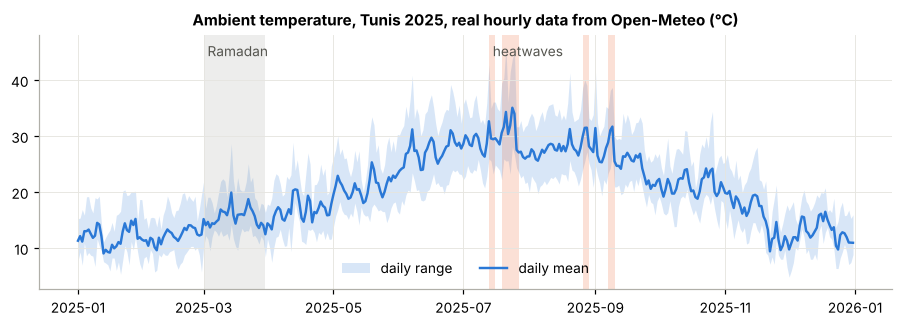

In [4]:
fig, ax = plt.subplots(figsize=(10, 3))
daily = ctx.ambient_temp_c.resample("D").agg(["min", "max", "mean"])
ax.fill_between(daily.index, daily["min"], daily["max"], color=C["blue"], alpha=0.18, lw=0, label="daily range")
ax.plot(daily.index, daily["mean"], color=C["blue"], label="daily mean")
ram = ctx[ctx.is_ramadan].index
ax.axvspan(ram.min(), ram.max(), color=C["gray"], alpha=0.15, lw=0)
ax.text(ram.min(), ax.get_ylim()[1] * 0.92, " Ramadan", color="#55554f")
hw = ctx.heatwave.resample("D").max().astype(bool)
runs = (hw != hw.shift()).cumsum()[hw]
for _, g in hw[hw].groupby(runs):
    ax.axvspan(g.index[0], g.index[-1] + pd.Timedelta(days=1), color=C["orange"], alpha=0.2, lw=0)
ax.text(hw[hw].index[0], ax.get_ylim()[1] * 0.92, " heatwaves", color="#55554f")
ax.set_title("Ambient temperature, Tunis 2025, real hourly data from Open-Meteo (°C)"); ax.legend(loc="lower center", ncol=2)
plt.show()

## 3. Household load: seasons and Ramadan

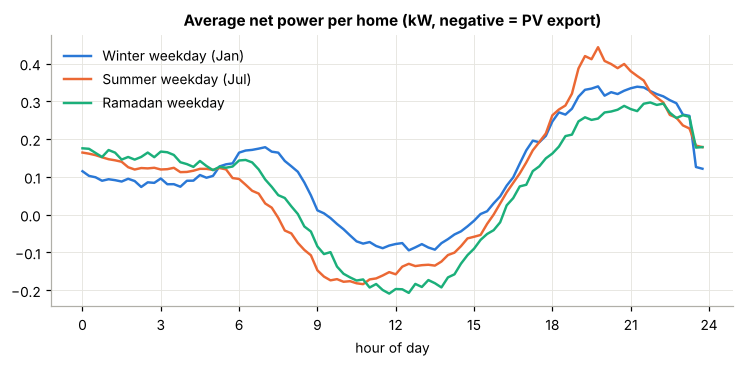

Annual imported energy per home (kWh): {'min': 484.0, '50%': 1235.0, 'max': 2651.0}


In [5]:
m = truth.merge(ctx[["is_weekend", "is_holiday", "is_ramadan"]], left_on="timestamp", right_index=True)
m["hour"] = m.timestamp.dt.hour + m.timestamp.dt.minute / 60
m["month"] = m.timestamp.dt.month
work = ~(m.is_weekend | m.is_holiday)
groups = {
    "Winter weekday (Jan)": C["blue"],
    "Summer weekday (Jul)": C["orange"],
    "Ramadan weekday": C["aqua"],
}
sel = {"Winter weekday (Jan)": work & (m.month == 1) & ~m.is_ramadan,
       "Summer weekday (Jul)": work & (m.month == 7),
       "Ramadan weekday": work & m.is_ramadan}
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, col in groups.items():
    prof = m[sel[k]].groupby("hour").active_power_kw.mean()
    ax.plot(prof.index, prof.values, color=col, label=k)
ax.set_xlabel("hour of day"); ax.set_title("Average net power per home (kW, negative = PV export)")
ax.set_xticks(range(0, 25, 3)); ax.legend()
plt.show()
ann = truth.groupby("meter_id", observed=True).active_power_kw.apply(lambda s: s.clip(lower=0).sum() * 0.25)
print("Annual imported energy per home (kWh):", ann.describe()[["min", "50%", "max"]].round(0).to_dict())

The lunch and evening peaks, the summer air-conditioning load and the Ramadan shift (suhoor around
03:00, a dip at iftar, a late-evening peak) are all there. Midday PV export pulls the average down.

## 3b. Calibration against real data

The household model was calibrated so the clean baseline matches three public references
(`inputs/README.md`): the Tunisian household benchmark (about 1,450 kWh a year), STEG's national
monthly sales (2013 to 2021) and the weekday load curve of residential district feeders in Laayoune,
Morocco (10-minute data, 2022 to 2024).

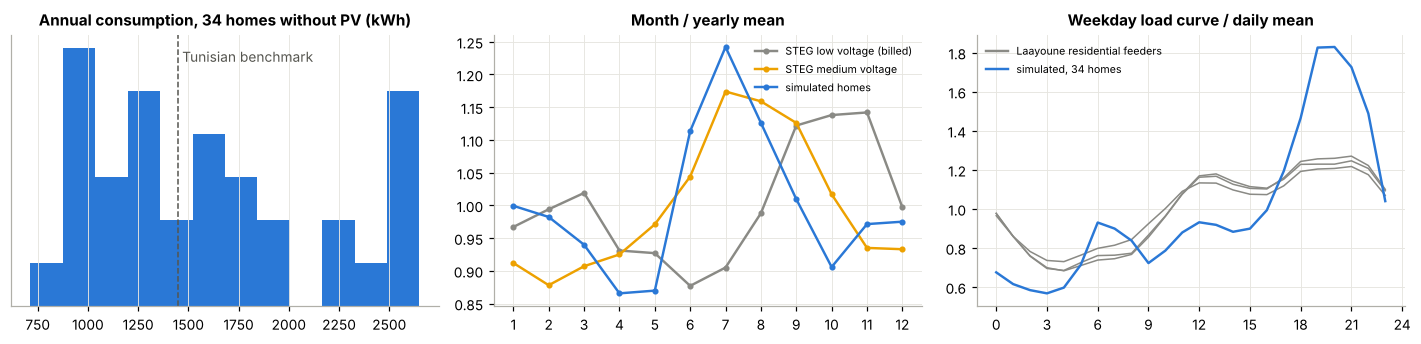

median home 1478 kWh/yr | summer peak month 1.24x | night (02-05h) 0.58x | evening peak 1.83x


In [6]:
INP = next(p for p in [Path("../inputs"), Path("inputs")] + [Path(p).parent for p in glob.glob("/kaggle/input/**/inputs/steg_monthly_index_2013_2021.csv", recursive=True)] if p.exists())
steg = pd.read_csv(INP / "steg_monthly_index_2013_2021.csv")
mor = pd.read_csv(INP / "morocco_laayoune_hourly_profile.csv")
# homes without PV: what the meter sees is the household's whole consumption
nopv = meta.loc[~meta.has_pv, "meter_id"]
cons = truth[truth.meter_id.isin(nopv)]
ann_c = cons.groupby("meter_id", observed=True).active_power_kw.sum() * 0.25
tot = cons.groupby("timestamp").active_power_kw.sum()
mo = tot.groupby(tot.index.month).mean(); mo = mo / mo.mean()
wd = tot[tot.index.dayofweek < 5]
hr = wd.groupby(wd.index.hour).mean(); hr = hr / hr.mean()

fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
axs[0].hist(ann_c, bins=12, color=C["blue"])
axs[0].axvline(1450, color="#55554f", ls="--", lw=1); axs[0].text(1450, axs[0].get_ylim()[1] * 0.9, " Tunisian benchmark", color="#55554f")
axs[0].set_title(f"Annual consumption, {len(nopv)} homes without PV (kWh)"); axs[0].set_yticks([])
axs[1].plot(steg.month, steg.steg_bt_index, color=C["gray"], marker="o", ms=3, label="STEG low voltage (billed)")
axs[1].plot(steg.month, steg.steg_mt_index, color=C["yellow"], marker="o", ms=3, label="STEG medium voltage")
axs[1].plot(mo.index, mo.values, color=C["blue"], marker="o", ms=3, label="simulated homes")
axs[1].set_xticks(range(1, 13)); axs[1].set_title("Month / yearly mean"); axs[1].legend(fontsize=7)
for z, col in zip(["laayoune_zone2", "laayoune_zone3", "laayoune_zone4"], [C["gray"]] * 3):
    axs[2].plot(mor.hour, mor[z], color=col, lw=1)
axs[2].plot([], [], color=C["gray"], label="Laayoune residential feeders")
axs[2].plot(hr.index, hr.values, color=C["blue"], label=f"simulated, {len(nopv)} homes")
axs[2].set_xticks(range(0, 25, 3)); axs[2].set_title("Weekday load curve / daily mean"); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
night = wd.between_time("02:00", "04:59").mean() / wd.mean()
print(f"median home {ann_c.median():.0f} kWh/yr | summer peak month {mo.max():.2f}x | night (02-05h) {night:.2f}x | evening peak {hr.max():.2f}x")

STEG's low-voltage sales are billed, so their summer peak shows up in September to November; the
medium-voltage series is metered monthly and peaks in July and August. The simulated months sit between
them. A district of thousands of customers is smoother than a few dozen homes, so the simulated daily curve
has a deeper night and a sharper evening peak than the Moroccan feeders, as expected; it keeps their
shape (quiet night, midday shoulder, peak at 20:00 to 21:00). Homes with PV are left out of these three
panels because their meters only see what the panels do not cover.

## 4. Physics: voltages, feeder profile, power identity, energy balance

share of intervals inside 207-253 V: 0.9991


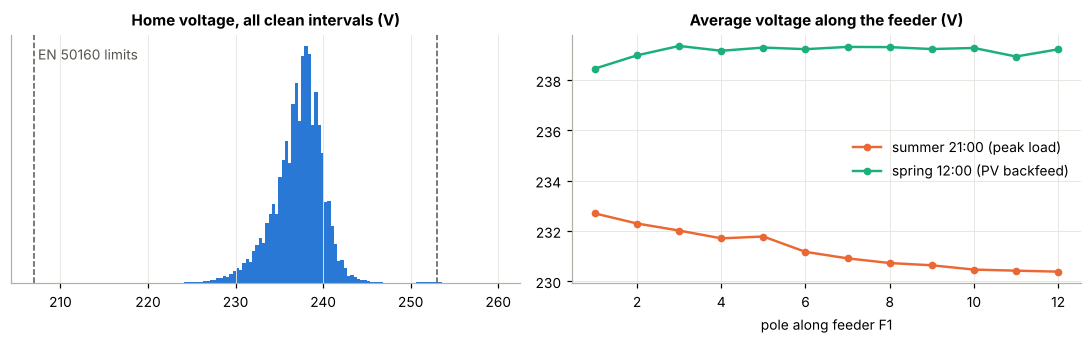

In [7]:
v = truth.voltage_v[truth.voltage_v > 50]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].hist(v, bins=120, color=C["blue"])
for lim in (207, 253):
    axs[0].axvline(lim, color="#55554f", lw=1, ls="--")
axs[0].set_title("Home voltage, all clean intervals (V)"); axs[0].set_yticks([])
axs[0].text(207, axs[0].get_ylim()[1] * 0.9, " EN 50160 limits", color="#55554f")
print(f"share of intervals inside 207-253 V: {((v > 207) & (v < 253)).mean():.4f}")

t = truth[truth.feeder == "F1"].copy()
t["hour"] = t.timestamp.dt.hour
summer = t.timestamp.dt.month.isin([7, 8])
spring = t.timestamp.dt.month.isin([4, 5])
for lab, mask, col in [("summer 21:00 (peak load)", summer & (t.hour == 21), C["orange"]),
                       ("spring 12:00 (PV backfeed)", spring & (t.hour == 12), C["aqua"])]:
    prof = t[mask].groupby("pole").voltage_v.mean()
    axs[1].plot(prof.index, prof.values, marker="o", ms=4, color=col, label=lab)
axs[1].set_xlabel("pole along feeder F1"); axs[1].set_title("Average voltage along the feeder (V)")
axs[1].legend()
plt.tight_layout(); plt.show()

Power identity |P| = V*I*PF on clean observed rows: median |residual| 0.0048, 99.9th pct 0.0281


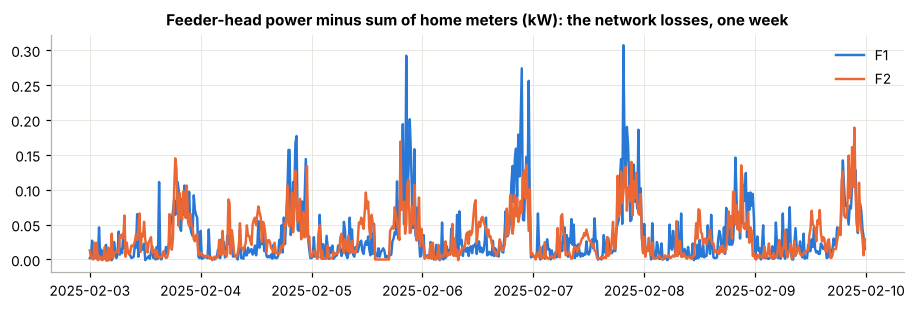

In [8]:
clean = meters[meters.is_anomaly == 0]
s = clean.voltage_v * clean.current_a / 1000
ok = s > 0.05
ident = (clean.active_power_kw.abs() - s * clean.power_factor)[ok] / s[ok]
print(f"Power identity |P| = V*I*PF on clean observed rows: median |residual| {ident.abs().median():.4f}, "
      f"99.9th pct {ident.abs().quantile(0.999):.4f}")

hp = head.groupby(["timestamp", "feeder"], observed=True).active_power_kw.sum()
mp = truth.groupby(["timestamp", "feeder"], observed=True).active_power_kw.sum()
gap = (hp - mp).unstack()
fig, ax = plt.subplots(figsize=(10, 2.8))
wk = gap.loc["2025-02-03":"2025-02-09"]
ax.plot(wk.index, wk["F1"], color=C["blue"], label="F1"); ax.plot(wk.index, wk["F2"], color=C["orange"], label="F2")
ax.set_title("Feeder-head power minus sum of home meters (kW): the network losses, one week"); ax.legend()
plt.show()

Clean data obeys the physics the detectors rely on: the power identity holds to within meter noise,
and the feeder balance gap is just the network losses, which follow the load. A data problem has to
break one of these relations; a real grid event keeps them.

## 5. Anomaly gallery: observed (what the meter reported) vs true

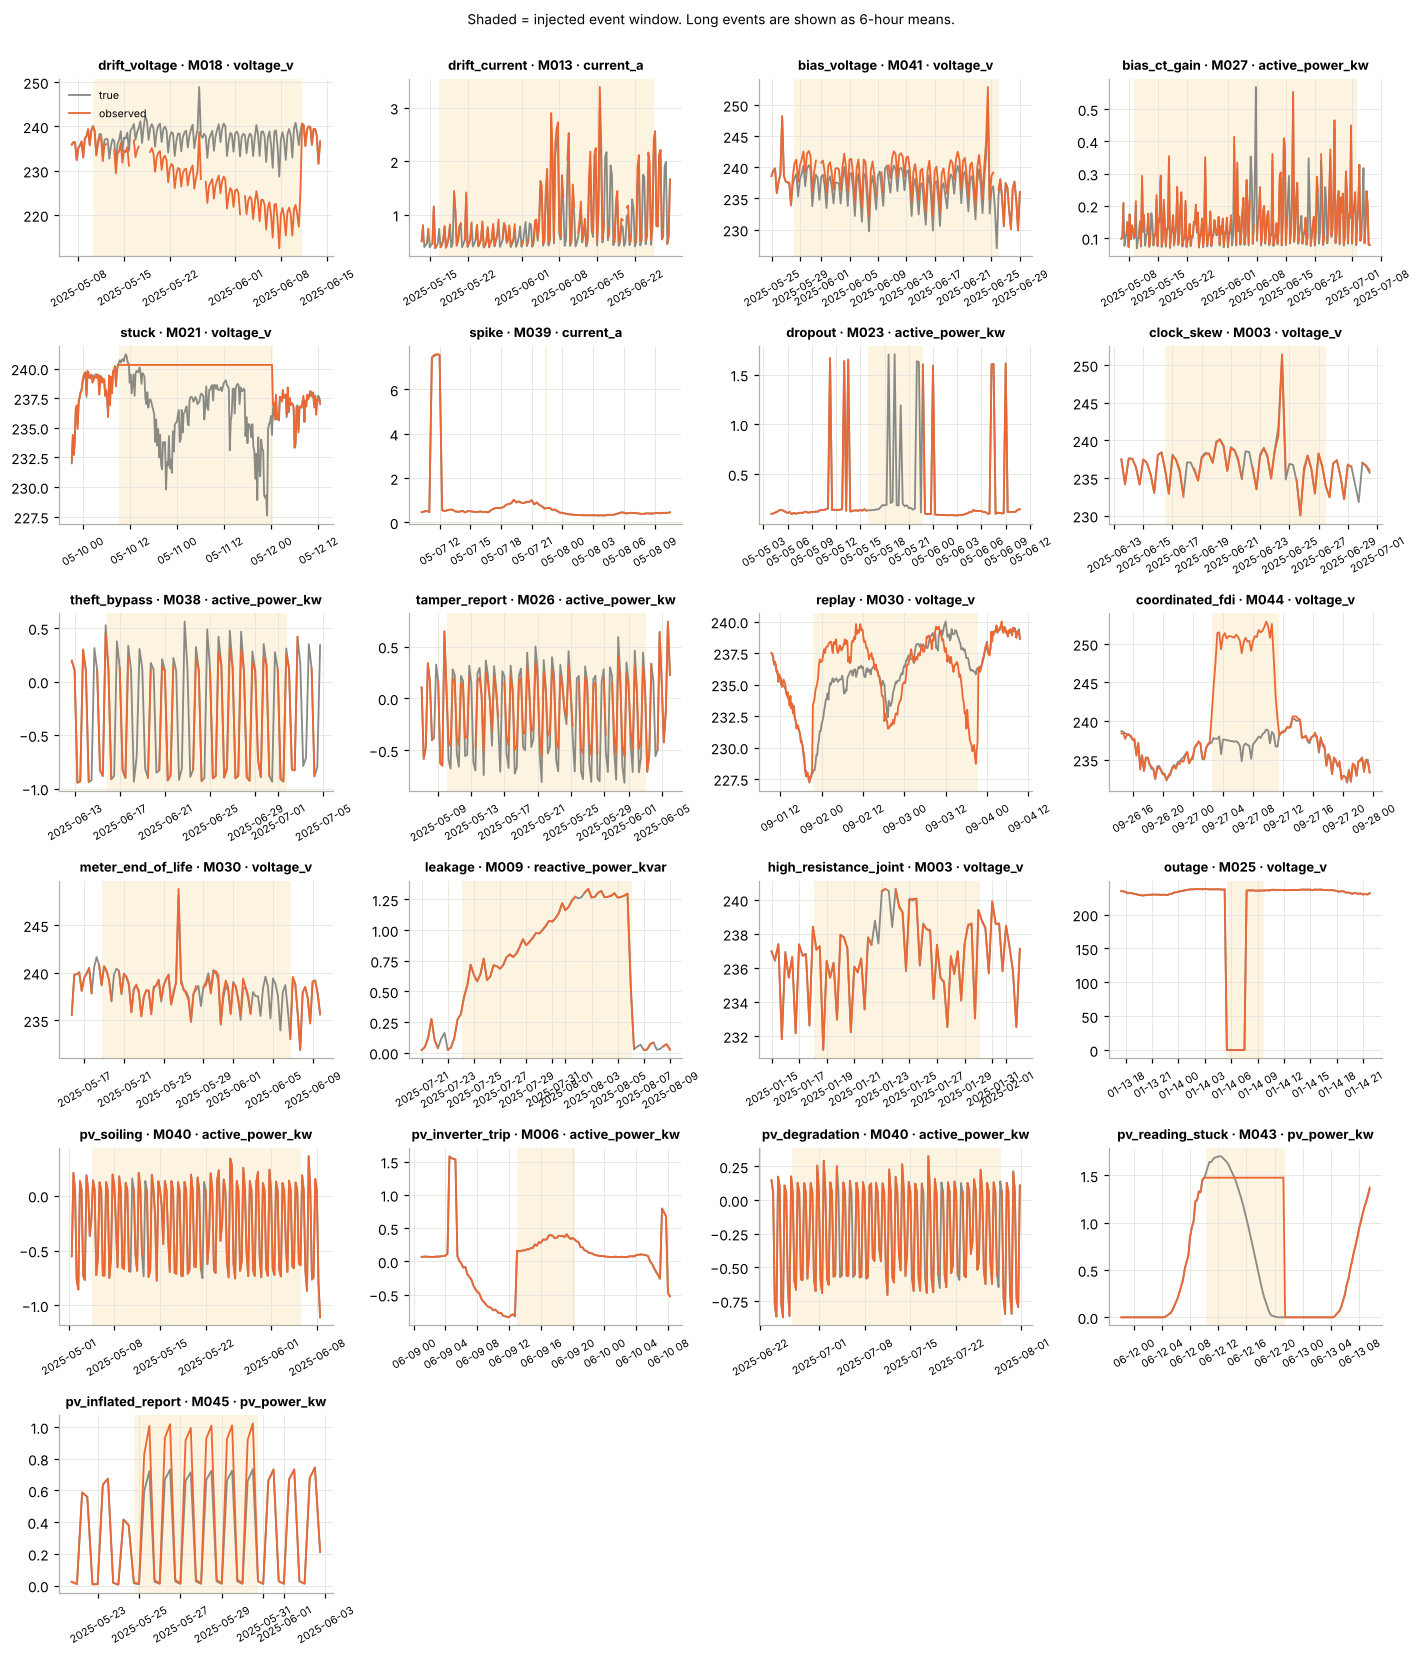

In [9]:
def show(ax, etype, channel, pad_h=12, which=0):
    e = events[events.anomaly_type == etype].sort_values("start").iloc[which]
    mid = (e.meters or "").split(";")[0] if isinstance(e.meters, str) else None
    a, b = e.start - pd.Timedelta(hours=pad_h), e.end + pd.Timedelta(hours=pad_h)
    long = (e.end - e.start) > pd.Timedelta(days=2)
    if long:
        a, b = e.start - pd.Timedelta(days=3), e.end + pd.Timedelta(days=3)
    o = meters[(meters.meter_id == mid) & meters.timestamp.between(a, b)].set_index("timestamp")[channel]
    tr = truth[(truth.meter_id == mid) & truth.timestamp.between(a, b)].set_index("timestamp")[channel]
    if long:
        o, tr = o.resample("6h").mean(), tr.resample("6h").mean()
    ax.plot(tr.index, tr.values, color=C["gray"], lw=1.2, label="true")
    ax.plot(o.index, o.values, color=C["orange"], lw=1.2, label="observed")
    ax.axvspan(e.start, e.end, color=C["yellow"], alpha=0.12, lw=0)
    ax.set_title(f"{etype} · {mid} · {channel}", fontsize=8.5)
    ax.tick_params(axis="x", labelsize=7, rotation=30)

panels = [("drift_voltage", "voltage_v"), ("drift_current", "current_a"), ("bias_voltage", "voltage_v"),
          ("bias_ct_gain", "active_power_kw"), ("stuck", "voltage_v"), ("spike", "current_a"),
          ("dropout", "active_power_kw"), ("clock_skew", "voltage_v"), ("theft_bypass", "active_power_kw"),
          ("tamper_report", "active_power_kw"), ("replay", "voltage_v"), ("coordinated_fdi", "voltage_v"),
          ("meter_end_of_life", "voltage_v"), ("leakage", "reactive_power_kvar"),
          ("high_resistance_joint", "voltage_v"), ("outage", "voltage_v"),
          ("pv_soiling", "active_power_kw"), ("pv_inverter_trip", "active_power_kw"), ("pv_degradation", "active_power_kw"),
          ("pv_reading_stuck", "pv_power_kw"), ("pv_inflated_report", "pv_power_kw")]
fig, axs = plt.subplots(6, 4, figsize=(13, 15))
for ax in axs.ravel()[len(panels):]:
    ax.axis("off")
for ax, (et, ch) in zip(axs.ravel(), panels):
    show(ax, et, ch)
axs[0, 0].legend(loc="upper left", fontsize=7)
plt.suptitle("Shaded = injected event window. Long events are shown as 6-hour means.", y=1.0, fontsize=9)
plt.tight_layout(); plt.show()

Where the true and observed lines overlap, the anomaly is **physical** (leakage, joint, outage, dusty or
tripped panels): the meter reports the truth and the grid itself changed. Where they split, the meter is lying. Note the
hard cases: current drift, CT gain error and bypass theft keep P = V·I·PF intact, so only the feeder
energy balance reveals them; the coordinated attack moves several meters together, like a real swell.

## 6. Hard negative: the heatwave is real demand, not an anomaly

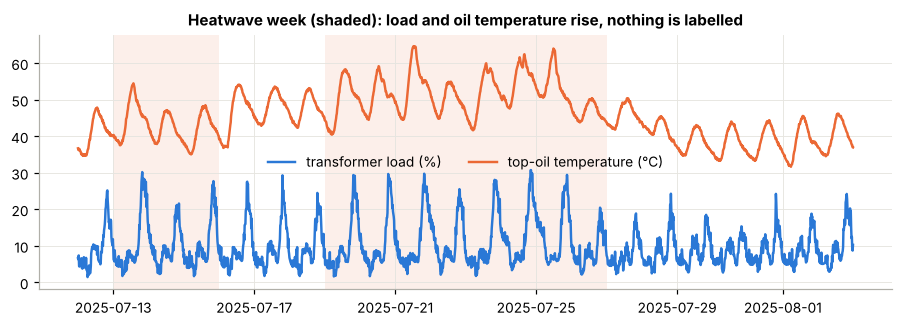

In [10]:
fig, ax = plt.subplots(figsize=(10, 3))
w = tx.set_index("timestamp").loc["2025-07-12":"2025-08-02"]
ax.plot(w.index, w.load_pct, color=C["blue"], label="transformer load (%)")
ax.plot(w.index, w.top_oil_temp_c, color=C["orange"], label="top-oil temperature (°C)")
for d in ctx.loc["2025-07-12":"2025-08-02"].heatwave.resample("D").max().pipe(lambda s: s[s.astype(bool)]).index:
    ax.axvspan(d, d + pd.Timedelta(days=1), color=C["orange"], alpha=0.1, lw=0)
ax.set_title("Heatwave week (shaded): load and oil temperature rise, nothing is labelled"); ax.legend(ncol=2)
plt.show()